# PAP-Auswertung – Template

**Hinweise an Tutor:innen**
Die Rechner sind alle vorbereitete Templates und nicht primär Teil der Auswertung, sondern stehen lediglich zur Nachvollziehbarkeit der Berechnungen zur Verfügung.
Die eigentliche Auswertung beginnt stets ab [Teil 2](#teil_2)

**Ablauf**
1. Messwerte in `messwerte.xlsx` eintragen (Aufbau siehe Blatt `_Anleitung` und Beispielblatt `Aufgabe1`).
2. **Teil 0** – Einstellungen prüfen.
3. **Teil 1** – Rechner einmal komplett ausführen (nicht ändern).
4. **Teil 2** – Auswertung: die Beispielzellen kopieren und anpassen.
5. **Teil 3** – Export: schreibt `export/ergebnisse.tex`.

Alles, was das Notebook schreibt, landet in `export/` und nur dort. Der Ordner kann jederzeit gelöscht werden – ein Durchlauf erzeugt ihn neu.

| Rechner | Aufruf | Export |
|---|---|---|
| R1 Rundung | `runde(x, dx)`, `pm(x, dx)`, `pm_tex(x, dx)`, `fehler_str(dx)` | – |
| R2 Ergebnis ablegen | `erg("name", wert, fehler, "Einheit")` | `\erg{name}` |
| R3 Excel einlesen | `T, K = lade()` → `T["tabelle"]["spalte"]`, `K["konstante"]` | – |
| R4 Tabelle | `tabelle("name", T["..."])` oder `tabelle("name", {Kopf: Spalte, ...})`, `konstanten_tabelle(K)` | `export/tabellen/` |
| R5 Mittelwert | `mittel("name", spalte)` | `\erg{name}` |
| R6 Gauß | `gauss("name", "formel", einheit=..., x=..., y=...)` | `export/formeln/`, `export/budget/`, `\erg{name}` |
| R7 Gerätefehler | `geraet(wert, prozent, digits, aufloesung)` | – |
| R8 Geraden | `regression("name", x, y)`, `zwei_punkte("name", p0, p1)` | `\erg{name_m}`, `\erg{name_b}` |
| R9 Ablesen | `ablesen(y, dy, gerade, *fehlergeraden)`, `aus_tabelle(y, dy, x_tab, y_tab)` | – |
| R10 σ-Vergleich | `sigma("name", a, b)` | `\ergsig{name}` |
| R11 Diagramm | `zeichne_fit(ax, fit, ...)`, `legende(ax)`, `speichern(fig, "name")` | `export/diagramme/` |
| R12 Export | `export_ergebnisse()` | `export/ergebnisse.tex` |

**Größen übergeben:** Überall, wo ein Rechner eine Größe braucht, geht eine eingelesene Spalte/Konstante (`T[..][..]`, `K[..]`), ein Tupel `(Wert, Fehler)`, eine Zahl/ein Array (= exakt, ohne Fehler) oder der Name eines abgelegten Ergebnisses als Text (`"fit_V_m"`).

Gerechnet wird immer mit den ungerundeten Werten, gerundet wird erst bei Ausgabe und Export.

## Teil 0 – Einstellungen

In [1]:
EXCEL        = "messwerte.xlsx"   # Messtabellen
EXPORT       = "export"           # Ordner für alle Exporte
SPRACHE      = "de"               # "de" oder "en": σ-Satz, Tabellenköpfe von Budget und Konstanten
GAUSS_ANSATZ = True               # Zeile mit dem allgemeinen Gauß-Ansatz im Formel-Export

## Teil 1 – Rechner
Einmal ausführen, nicht ändern.

In [2]:
import os, re
from types import SimpleNamespace
from decimal import Decimal, ROUND_CEILING, ROUND_HALF_UP
import numpy as np
import sympy as sp
import openpyxl
import matplotlib.pyplot as plt
from IPython.display import Markdown, Math, display

### R1 Rundung
1. Fehler immer aufrunden, nie abrunden
2. Beginnt der Fehler mit 1 oder 2: zwei signifikante Stellen, sonst eine
3. Messwert bis zur letzten Stelle des gerundeten Fehlers (kaufmännisch)

`runde(x, dx)` → `("Wert", "Fehler")`, `pm` → `"x ± dx"`, `pm_tex` → `"x \pm dx"`, `fehler_str(dx)` → nur die gerundeten Fehler als Text.

In [3]:
def _letzte_stelle(d):
    e     = d.adjusted()                    # Zehnerpotenz der ersten Ziffer
    erste = int(d.scaleb(-e))               # erste Ziffer
    return e - 1 if erste <= 2 else e

def runde(x, dx):
    d = Decimal(f"{abs(dx):.12g}")          # Gleitkomma-Rauschen weg
    if d == 0:
        raise ValueError("Fehler ist 0")
    stelle = _letzte_stelle(d)
    d = d.quantize(Decimal(1).scaleb(stelle), ROUND_CEILING)
    while _letzte_stelle(d) != stelle:      # Aufrunden kann die erste Ziffer ändern -> Regel 2 nochmal
        stelle = _letzte_stelle(d)
        d = d.quantize(Decimal(1).scaleb(stelle), ROUND_CEILING)
    xr = Decimal(f"{x:.15g}").quantize(Decimal(1).scaleb(stelle), ROUND_HALF_UP)
    if xr == 0:
        xr = abs(xr)                        # kein "-0.0"
    return f"{xr:f}", f"{d:f}"

pm         = lambda x, dx: " ± ".join(runde(x, dx))
pm_tex     = lambda x, dx: r" \pm ".join(runde(x, dx))
fehler_str = lambda dx: [runde(d, d)[1] for d in np.atleast_1d(dx)]

# Tests aus 01_Rundung
for x_, dx_, soll in [(953, 2, ("953.0", "2.0")), (-62.34, 0.71, ("-62.3", "0.8")),
                      (-191.7, 8.6, ("-192", "9")), (1.23456, 0.291, ("1.2", "0.3")),
                      (10.44, 0.96, ("10.4", "1.0")), (0.1 + 0.2, 0.1 + 0.2, ("0.3", "0.3")),
                      (1252.58, 2.031, ("1252.6", "2.1")), (-0.04, 0.3, ("0.0", "0.3"))]:
    assert runde(x_, dx_) == soll, (x_, dx_, runde(x_, dx_), soll)

### R2 Ergebnis-Register
Jeder Rechner legt seine Ergebnisse hier ab; `export_ergebnisse()` (R12) macht daraus LaTeX-Makros.
Eigene Werte ablegen: `erg("name", wert, fehler, "Einheit")`.

Einheiten wie in siunitx (`m/s^2`, `kg.m^2`, `\milli\volt`); `°C`, `Ω`, `µ`, `%`, `²`, `³` werden automatisch übersetzt.

In [4]:
ERG = {}   # Name -> (Wert, Fehler, Einheit, Herkunft)   ->  \erg{Name}
SIG = {}   # Name -> sigma-Abweichung                     ->  \ergsig{Name}

EINHEITEN = {"°C": r"\celsius", "°": r"\degree", "Ω": r"\ohm", "µ": r"\micro ", "μ": r"\micro ",
             "%": r"\percent", "²": "^2", "³": "^3"}

def einheit_tex(e):
    for alt, neu in EINHEITEN.items():
        e = e.replace(alt, neu)
    return e.strip()

def erg(name, wert, fehler=None, einheit="", herkunft="", zeigen=True):
    fehler = None if fehler is None or fehler == 0 else float(fehler)
    ERG[name] = (float(wert), fehler, einheit, herkunft)
    if zeigen:
        print(f"{name} = ({pm(wert, fehler)}) {einheit}" if fehler else f"{name} = {wert:.10g} {einheit}")

### R3 Excel einlesen
`T, K = lade()` liest alle Blätter von `EXCEL`:
- **Blatt `Konstanten`**: Spalten `Name | Wert | Fehler | Einheit | Quelle | Beschreibung` → `K["name"]`, landen auch im Ergebnis-Register (`\erg{name}`).
- **Blatt ohne `#`-Zelle**: das ganze Blatt ist eine Tabelle, Name = Blattname.
- **Blatt mit `#name`-Zellen in Spalte A**: jede `#`-Zelle startet eine Tabelle; nächste Zeile = Kopf, dann Daten bis zur ersten Leerzeile. Text rechts neben `#name` = Beschreibung.
- **Kopf**: `t1 [ms]`, Fehler in der Spalte `Δt1 [ms]` (gleiche Einheit). Nur erste Zeile gefüllt → gilt für die ganze Spalte; alle gefüllt → je Zeile; teilweise → Fehlermeldung.
- Blätter, deren Name mit `_` beginnt, werden ignoriert.

Zugriff: `T["fall_V"]["t1"]` ist eine `Spalte` mit `.w` (Werte), `.f` (Fehler), `.einheit`; `w, f = T["fall_V"]["t1"]` entpackt.

In [5]:
class Spalte:
    """Messgröße: .w Werte, .f Fehler (None = exakt), .einheit, .name, .herkunft  --  w, f = spalte"""
    def __init__(self, name, w, f=None, einheit="", herkunft=""):
        self.name, self.w, self.f, self.einheit, self.herkunft = name, w, f, einheit, herkunft
        self.beschreibung = ""
    def __iter__(self):
        return iter((self.w, self.f))
    def __repr__(self):
        if np.ndim(self.w) == 0:
            return f"{self.name} = " + (f"({pm(self.w, self.f)}) {self.einheit}" if self.f else f"{self.w:.10g} {self.einheit}")
        return f"{self.name} [{self.einheit}]: {len(self.w)} Werte" + ("" if self.f is None else " mit Fehler")

class Tabelle(dict):
    """Eingelesene Excel-Tabelle {Spaltenname: Spalte}; dazu .name und .beschreibung"""

def _leer(zeile):
    return all(c is None or str(c).strip() == "" for c in zeile)

def _ist_marker(c):
    return isinstance(c, str) and c.strip().startswith("#")

def _zahl(x):
    if isinstance(x, str):
        x = x.strip().replace(",", ".")
    try:
        return float(x)
    except (TypeError, ValueError):
        return np.nan

def _kopf(text):
    m = re.match(r"^\s*(.*?)\s*(?:\[(.*)\])?\s*$", str(text))
    return m.group(1), (m.group(2) or "").strip()

def _tabelle_lesen(blatt, name, zeilen, z0):
    """zeilen = Kopf + Daten, z0 = Index der Kopfzeile (Excel-Zeile z0 + 1)."""
    kopf, daten = zeilen[0], zeilen[1:]
    spalten = {j: _kopf(k) for j, k in enumerate(kopf) if k is not None and str(k).strip()}
    zelle = lambda z, j: z[j] if j < len(z) else None
    tab = Tabelle(); tab.name = name
    for j, (n, e) in spalten.items():                       # Wertespalten
        if n.startswith("Δ"):
            continue
        roh = [zelle(z, j) for z in daten]
        w = np.array([_zahl(x) for x in roh])
        if np.isnan(w).all():                               # Textspalte (Nr. als Text, Bemerkung, ...)
            w = np.array(["" if x is None else str(x) for x in roh], dtype=object)
        tab[n] = Spalte(n, w, None, e, f"{blatt}/{name}")
    for j, (n, e) in spalten.items():                       # Fehlerspalten
        if not n.startswith("Δ"):
            continue
        ziel = n[1:].strip()
        if ziel not in tab:
            raise ValueError(f"{blatt}/{name}: zu '{n}' gibt es keine Spalte '{ziel}'")
        if e != tab[ziel].einheit:
            raise ValueError(f"{blatt}/{name}: Einheit von {n} [{e}] ist nicht die von {ziel} [{tab[ziel].einheit}]")
        f = np.array([_zahl(zelle(z, j)) for z in daten])
        voll = ~np.isnan(f)
        if voll[0] and not voll[1:].any():
            f = np.full(len(f), f[0])                       # nur erste Zeile -> gilt für alle
        elif not voll.all():
            fehlt = [z0 + 2 + i for i in np.where(~voll)[0]]
            raise ValueError(f"{blatt}/{name}: Spalte '{n}' ist nur teilweise gefüllt (leer in Excel-Zeile "
                             f"{', '.join(map(str, fehlt))}). Entweder nur die erste Zeile oder alle Zeilen füllen.")
        tab[ziel].f = f
    return tab

def _konstanten(z, blatt):
    kopf = [str(c).strip().lower() if c is not None else "" for c in z[0]]
    idx  = lambda *namen: next((kopf.index(n) for n in namen if n in kopf), None)
    i_n, i_w, i_f = idx("name"), idx("wert", "value"), idx("fehler", "error")
    i_e, i_q, i_b = idx("einheit", "unit"), idx("quelle", "source"), idx("beschreibung", "description")
    K = {}
    for r, zeile in enumerate(z[1:], start=2):
        hol = lambda i: zeile[i] if i is not None and i < len(zeile) else None
        if _leer(zeile) or hol(i_n) in (None, ""):
            continue
        n, w, f = str(hol(i_n)).strip(), _zahl(hol(i_w)), _zahl(hol(i_f))
        if np.isnan(w):
            raise ValueError(f"{blatt}, Zeile {r}: Wert von '{n}' fehlt")
        s = Spalte(n, w, None if np.isnan(f) or f == 0 else f, str(hol(i_e) or "").strip(), str(hol(i_q) or "").strip())
        s.beschreibung = str(hol(i_b) or "").strip()
        K[n] = s
        erg(n, w, s.f, s.einheit, s.herkunft or blatt, zeigen=False)
    return K

def lade(datei=None):
    datei = datei or EXCEL
    wb = openpyxl.load_workbook(datei, data_only=True)
    T, K = {}, {}
    for ws in wb.worksheets:
        blatt = ws.title
        if blatt.startswith("_"):
            continue
        z = [list(r) for r in ws.iter_rows(min_row=1, max_row=ws.max_row, min_col=1,
                                           max_col=ws.max_column, values_only=True)]
        if not z or all(_leer(r) for r in z):
            continue
        if blatt.strip().lower() in ("konstanten", "constants"):
            K.update(_konstanten(z, blatt))
            continue
        marker = [i for i, r in enumerate(z) if _ist_marker(r[0])]
        if marker:
            bloecke = [(z[i][0].strip()[1:].strip(), i + 1, z[i][1] if len(z[i]) > 1 else None) for i in marker]
        else:
            bloecke = [(blatt, next(i for i, r in enumerate(z) if not _leer(r)), None)]
        for name, k, beschr in bloecke:
            ende = k + 1
            while ende < len(z) and not _leer(z[ende]) and not _ist_marker(z[ende][0]):
                ende += 1
            if name in T:
                raise ValueError(f"Tabelle '{name}' gibt es doppelt")
            T[name] = _tabelle_lesen(blatt, name, z[k:ende], k)
            T[name].beschreibung = beschr or ""
    for name, tab in T.items():
        n = max(len(s.w) for s in tab.values())
        sp_ = ", ".join(f"{s.name} [{s.einheit}]" + ("±" if s.f is not None else "") for s in tab.values())
        print(f"T[{name!r}]  {n} Zeilen:  {sp_}")
    for s in K.values():
        print(f"K[{s.name!r}]  {s!r}")
    return T, K

### R4 Tabellen-Export
- `tabelle("name", T["fall_V"])` – Excel-Tabelle so wie sie ist (leere Textspalten fallen weg).
- `tabelle("name", {Kopf: Daten, ...})` – eigene Zusammenstellung. Kopf als LaTeX, Einheit in `[ ]` (z. B. `r"$\bar t^2$ [s^2]"`); Daten = Spalte, `(Werte, Fehler)` oder Liste/Array (ohne Fehler; Text wird unverändert übernommen, z. B. `fehler_str(...)`).
- `konstanten_tabelle(K)` – Tabelle der Konstanten für „Verwendete Konstanten“.

Werte mit Fehler → `\num{x \pm dx}` (PAP-Rundung). Ergebnis: `export/tabellen/<name>.tex`, einbinden mit `\input{export/tabellen/<name>}` in einer `table`-Umgebung.

In [6]:
TEXT_SPALTEN = {"Nr", "Nr.", "#", "Bemerkung", "Messung", "Remark"}

def _kopf_tex(name, einheit):
    if "$" in name or "\\" in name or name in TEXT_SPALTEN or not name.isidentifier():
        sym = name
    else:
        sym = f"${sp.latex(sp.Symbol(name))}$"
    return f"{sym} [\\unit{{{einheit_tex(einheit)}}}]" if einheit else sym

def _zelle(w, f, tex=True):
    if isinstance(w, str):
        return w
    if w is None or np.isnan(w):
        return ""
    if f is None or np.isnan(f) or f == 0:
        return f"{w:.10g}"
    return r"\num{" + pm_tex(w, f) + "}" if tex else pm(w, f)

def _schreibe(ordner, name, text):
    os.makedirs(f"{EXPORT}/{ordner}", exist_ok=True)
    with open(f"{EXPORT}/{ordner}/{name}.tex", "w", encoding="utf-8") as fh:
        fh.write(text)

def tabelle(name, spalten):
    kopf, daten = [], []
    if isinstance(spalten, Tabelle):
        for s in spalten.values():
            if s.w.dtype == object and all(x == "" for x in s.w):
                continue
            kopf.append(_kopf_tex(s.name, s.einheit))
            daten.append((s.w, s.f))
    else:
        for k, v in spalten.items():
            n, e = _kopf(k)
            kopf.append(f"{n} [\\unit{{{einheit_tex(e)}}}]" if e else n)
            if isinstance(v, (Spalte, tuple)):
                w, f = v
            else:
                w, f = v, None
            daten.append((w, f))
    daten = [(np.atleast_1d(w), None if f is None else np.broadcast_to(np.atleast_1d(f), np.shape(np.atleast_1d(w))))
             for w, f in daten]
    n = max(len(w) for w, _ in daten)
    hol = lambda a, i: a[i] if a is not None and i < len(a) else None
    zeilen = [[_zelle(hol(w, i), hol(f, i)) for w, f in daten] for i in range(n)]
    tex = [r"\begin{tabular}{" + "c" * len(kopf) + "}", r"\hline", " & ".join(kopf) + r" \\", r"\hline"]
    tex += [" & ".join(z) + r" \\" for z in zeilen]
    tex += [r"\hline", r"\end{tabular}"]
    _schreibe("tabellen", name, "\n".join(tex) + "\n")
    vorschau = "| " + " | ".join(kopf) + " |\n|" + "---|" * len(kopf) + "\n"
    vorschau += "".join("| " + " | ".join(_zelle(hol(w, i), hol(f, i), tex=False) for w, f in daten) + " |\n" for i in range(n))
    display(Markdown(f"**{EXPORT}/tabellen/{name}.tex**\n\n" + vorschau))

def konstanten_tabelle(K, name="konstanten"):
    kopf = {"de": ["Größe", "Symbol", "Wert", "Quelle"], "en": ["Quantity", "Symbol", "Value", "Source"]}[SPRACHE]
    tex = [r"\begin{tabular}{llcl}", r"\hline", " & ".join(kopf) + r" \\", r"\hline"]
    for s in K.values():
        zahl = pm_tex(s.w, s.f) if s.f else f"{s.w:.10g}"
        wert = rf"\qty{{{zahl}}}{{{einheit_tex(s.einheit)}}}" if s.einheit else rf"\num{{{zahl}}}"
        tex.append(f"{s.beschreibung} & ${sp.latex(sp.Symbol(s.name))}$ & {wert} & {s.herkunft}" + r" \\")
    tex += [r"\hline", r"\end{tabular}"]
    _schreibe("tabellen", name, "\n".join(tex) + "\n")
    print(f"-> {EXPORT}/tabellen/{name}.tex")

### R5 Mittelwert einer Messreihe
`mittel("name", werte, geraet=None)` – Mittelwert $\bar x$, $S_E$, $S_M = S_E/\sqrt{N}$; Fehler des Mittelwerts $\Delta\bar x = \sqrt{S_M^2 + \Delta_\mathrm{Gerät}^2}$.
Der Gerätefehler kommt aus der Δ-Spalte in Excel (muss für alle Werte gleich sein) oder aus `geraet=...`; `geraet=0` → nur $S_M$.
Werte, die mehr als 2 bzw. 3 $S_E$ vom Mittelwert abweichen, werden markiert.

In [7]:
def _als_wf(v):
    """Spalte, (Wert, Fehler), Zahl/Array (exakt) oder Name aus ERG  ->  (w, f) als Arrays, f = 0 für exakt."""
    if isinstance(v, str):
        if v not in ERG:
            raise KeyError(f"'{v}' ist nicht im Ergebnis-Register")
        w, f = ERG[v][:2]
    elif isinstance(v, (Spalte, tuple)):
        w, f = v
    else:
        w, f = v, None
    w = np.asarray(w, dtype=float)
    f = np.zeros_like(w) if f is None else np.asarray(f, dtype=float) * np.ones_like(w)
    return w, f

def _einheit(v):
    if isinstance(v, Spalte):
        return v.einheit
    if isinstance(v, str) and v in ERG:
        return ERG[v][2]
    return ""

def mittel(name, werte, geraet=None, einheit=None):
    w, f = _als_wf(werte)
    if geraet is None:
        if np.any(f) and not np.allclose(f, f[0]):
            raise ValueError(f"{name}: Gerätefehler ist nicht für alle Werte gleich -> geraet=... angeben")
        geraet = f[0]
    einheit = _einheit(werte) if einheit is None else einheit
    n, mw = len(w), w.mean()
    S_E = w.std(ddof=1)
    S_M = S_E / np.sqrt(n)
    ges = np.hypot(S_M, geraet)
    for i, xi in enumerate(w, 1):
        k = abs(xi - mw) / S_E if S_E > 0 else 0
        if k > 2:
            print(f"  Wert {i} = {xi:g} liegt {k:.1f} S_E vom Mittelwert" + ("  -> Ausreißer prüfen!" if k > 3 else ""))
    if n < 5:
        print(f"  Achtung: nur N = {n} Werte, S_E ist selbst sehr unsicher")
    print(f"  N = {n},  S_E = {S_E:.4g},  S_M = {S_M:.4g},  Gerät = {geraet:.4g}  ->  sqrt(S_M² + Gerät²) = {ges:.4g} {einheit}")
    erg(name, mw, ges, einheit, f"Mittelwert, N = {n}")
    return Spalte(name, mw, ges, einheit)

### R6 Gauß'sche Fehlerfortpflanzung
`gauss("name", "formel", einheit="", symbol=None, tex=None, **größen)`
- Formel als Text mit Python-Syntax (`**` für Potenzen, `sqrt`, `sin`, `pi`, `exp`, `log`); `lambda` wird zu λ.
- Jede Variable der Formel als Schlüsselwort übergeben: `l=K["l"]`, `T=T["pendel"]["T"]`, `m=(0.5, 0.01)`, `g=9.81` (exakt), `a="fit_V_m"` (aus dem Register).
- Funktioniert für Einzelwerte **und ganze Spalten** (dann ist das Ergebnis eine Spalte für `tabelle`).
- `symbol=r"a_\mathrm{th}"` – LaTeX-Symbol des Ergebnisses; `tex={"sin_phi": r"\sin\varphi"}` – LaTeX-Symbole der Eingangsgrößen.

Export: `export/formeln/<name>.tex` (Formel, Gauß-Ansatz, Ableitungen eingesetzt – ohne Zahlen; Labels `eq:<name>`, `eq:d<name>`), bei Einzelwerten zusätzlich `export/budget/<name>.tex` (Beiträge, Anteile, 20-%-Regel nur markiert) und `\erg{name}`.

In [8]:
def gauss(name, formel, einheit="", symbol=None, tex=None, **groessen):
    tex   = tex or {}
    syms  = {n: sp.Symbol(n) for n in groessen}
    expr  = sp.sympify(re.sub(r"\blambda\b", "lamda", formel), locals=syms)
    fehlt = {str(s) for s in expr.free_symbols} - set(groessen)
    if fehlt:
        raise ValueError(f"{name}: kein Wert für {', '.join(sorted(fehlt))}")
    namen = [n for n in groessen if syms[n] in expr.free_symbols]
    wf    = {n: _als_wf(groessen[n]) for n in namen}
    args  = [wf[n][0] for n in namen]
    rechne = lambda e: np.asarray(sp.lambdify([syms[n] for n in namen], e, "numpy")(*args), dtype=float)
    wert  = rechne(expr)
    abl, ableitung, beitrag = {}, {}, {}
    for n in namen:
        if np.any(wf[n][1]):
            abl[n]       = sp.simplify(sp.diff(expr, syms[n]))
            ableitung[n] = np.abs(rechne(abl[n])) * np.ones_like(wert)
            beitrag[n]   = ableitung[n] * wf[n][1]
    fehler = np.sqrt(sum(b**2 for b in beitrag.values())) if beitrag else np.zeros_like(wert)

    # --- Formel-Export (ohne Zahlen) ---
    sym_tex = {syms[n]: tex.get(n, sp.latex(syms[n])) for n in namen}
    lat = lambda e: sp.latex(e, symbol_names=sym_tex)
    S   = symbol or sp.latex(sp.Symbol(name))
    L   = lambda n: sym_tex[syms[n]]
    zeilen = [rf"{S} &= {lat(expr)} \label{{eq:{name}}}"]
    if abl:
        dS = rf"\Delta {S}"
        def term(n, a, quadrat):
            if a in (1, -1):
                return rf"\Delta {L(n)}"
            if a.is_number:
                return rf"{lat(sp.Abs(a))}\,\Delta {L(n)}"
            return rf"\left({lat(a)}\,\Delta {L(n)}\right)" if quadrat else rf"\left|{lat(a)}\right| \Delta {L(n)}"
        if len(abl) == 1:
            (n, a), = abl.items()
            ansatz  = rf"\left|\frac{{\partial {S}}}{{\partial {L(n)}}}\right| \Delta {L(n)}"
            konkret = term(n, a, False)
        else:
            ansatz  = r"\sqrt{" + " + ".join(rf"\left(\frac{{\partial {S}}}{{\partial {L(n)}}}\,\Delta {L(n)}\right)^2" for n in abl) + "}"
            konkret = r"\sqrt{" + " + ".join(term(n, a, True) + "^2" for n, a in abl.items()) + "}"
        if GAUSS_ANSATZ:
            zeilen += [rf"{dS} &= {ansatz} \nonumber", rf"&= {konkret} \label{{eq:d{name}}}"]
        else:
            zeilen += [rf"{dS} &= {konkret} \label{{eq:d{name}}}"]
    block = "\\begin{align}\n  " + " \\\\\n  ".join(zeilen) + "\n\\end{align}\n"
    _schreibe("formeln", name, block)
    display(Math(r"\begin{aligned}" + re.sub(r"\\label\{[^}]*\}|\\nonumber", "", " \\\\ ".join(zeilen)) + r"\end{aligned}"))

    # --- Ergebnis ---
    f_oder_none = lambda f: None if f == 0 else f
    if wert.ndim == 0:
        w, f = float(wert), float(fehler)
        erg(name, w, f_oder_none(f), einheit, f"gauss: {formel}")
        if beitrag:
            _budget(name, S, wf, ableitung, beitrag, f, L, groessen)
        return Spalte(name, w, f_oder_none(f), einheit)
    for i, (w, f) in enumerate(zip(wert, fehler), 1):
        print(f"  {i}: {name} = " + (f"({pm(w, f)}) {einheit}" if f else f"{w:.10g} {einheit}"))
    return Spalte(name, wert, fehler if np.any(fehler) else None, einheit)

def _budget(name, S, wf, ableitung, beitrag, fehler, L, groessen):
    gross = max(float(b) for b in beitrag.values())
    kopf = {"de": ["Größe", "Wert", r"$\Delta x_i$", rf"$\left|\partial {S}/\partial x_i\right|$", "Beitrag", "Anteil", ""],
            "en": ["Quantity", "Value", r"$\Delta x_i$", rf"$\left|\partial {S}/\partial x_i\right|$", "Contribution", "Share", ""]}[SPRACHE]
    tex = [r"\begin{tabular}{lcccccl}", r"\toprule", " & ".join(kopf) + r" \\", r"\midrule"]
    md_ = "| Größe | Wert | Δx | ∂/∂x | Beitrag | Anteil | 20-%-Regel |\n|---|---|---|---|---|---|---|\n"
    for n in sorted(beitrag, key=lambda n: -float(beitrag[n])):
        w, f = float(wf[n][0]), float(wf[n][1])
        d, b = float(ableitung[n]), float(beitrag[n])
        anteil = (b / fehler)**2 * 100
        klein  = b < 0.2 * gross
        e = einheit_tex(_einheit(groessen[n]))
        wert_t = rf"\qty{{{w:.6g}}}{{{e}}}" if e else rf"\num{{{w:.6g}}}"
        df_t   = rf"\qty{{{f:.3g}}}{{{e}}}" if e else rf"\num{{{f:.3g}}}"
        marke  = r"$<20\,\%$" if klein else ""
        tex.append(f"${L(n)}$ & {wert_t} & {df_t} & \\num{{{d:.3g}}} & \\num{{{b:.3g}}} & "
                   f"\\qty{{{anteil:.1f}}}{{\\percent}} & {marke}" + r" \\")
        md_ += f"| {n} | {w:.6g} | {f:.3g} | {d:.3g} | {b:.3g} | {anteil:.1f} % | {'< 20 % des größten' if klein else ''} |\n"
    tex += [r"\bottomrule", r"\end{tabular}"]
    _schreibe("budget", name, "\n".join(tex) + "\n")
    display(Markdown(md_))

### R7 Gerätefehler
`geraet(wert, prozent, digits, aufloesung)` – Spezifikation „± (p % vom Messwert + n Digits)“; `aufloesung` = Wert der letzten angezeigten Stelle (z. B. 0.001 bei 2.345 V). Funktioniert auch für Arrays.

In [9]:
def geraet(wert, prozent=0, digits=0, aufloesung=0):
    return np.abs(np.asarray(wert, dtype=float)) * prozent / 100 + digits * aufloesung

### R8 Geraden
**`regression("name", x, y, einheit_m="", einheit_b="", m_grob=None, x_fehler=True)`** – gewichtete Regression $y = m x + b$ (Gewicht $1/\Delta y_\mathrm{fit}^2$). x-Fehler gehen über $\Delta y_\mathrm{fit} = \sqrt{\Delta y^2 + (m_\mathrm{grob}\,\Delta x)^2}$ ein ($m_\mathrm{grob}$ aus den Endpunkten oder vorgegeben). Fehlergeraden: Steigung $m \pm \Delta m$ durch den Schwerpunkt. Rückgabe `fit` mit `fit.m, fit.dm, fit.b, fit.db, fit.dy_fit, fit.steil, fit.flach, fit.x_N, fit.dx_N`; legt `name_m` und `name_b` ab.

**`zwei_punkte("name", p0, p1, einheit_m="", einheit_b="")`** – Gerade durch zwei Punkte `p = (x, dx, y, dy)`, Fehlergeraden steil/flach durch die Fehlerkästen, Fehler = größere Abweichung (für positive Steigung und $x_0 < x_1$; sonst sind steil/flach vertauscht, der Fehler bleibt).

In [10]:
def lin_fit(x, y, dy):
    w = 1.0 / np.asarray(dy)**2
    S, Sx, Sy = w.sum(), (w*x).sum(), (w*y).sum()
    Sxx, Sxy  = (w*x*x).sum(), (w*x*y).sum()
    D = S*Sxx - Sx**2
    return (S*Sxy - Sx*Sy) / D, np.sqrt(S/D), (Sxx*Sy - Sx*Sxy) / D, np.sqrt(Sxx/D)

gerade = lambda x, m_, b_: m_ * x + b_

def _nullstelle(m, b, steil, flach):
    x_N = -b / m
    return x_N, max(abs(x_N + steil[1] / steil[0]), abs(x_N + flach[1] / flach[0]))

def regression(name, x, y, einheit_m="", einheit_b="", m_grob=None, x_fehler=True):
    x, dx = _als_wf(x)
    y, dy = _als_wf(y)
    if not np.all(dy) and not (x_fehler and np.all(dx)):
        raise ValueError(f"{name}: jeder Punkt braucht einen y-Fehler (Gewicht)")
    m_grob = (y[-1] - y[0]) / (x[-1] - x[0]) if m_grob is None else m_grob
    dy_fit = np.sqrt(dy**2 + (m_grob * dx)**2) if x_fehler else dy
    m, dm, b, db = lin_fit(x, y, dy_fit)
    durch_schwerpunkt = lambda m_: (m_, y.mean() - m_ * x.mean())
    fit = SimpleNamespace(m=m, dm=dm, b=b, db=db, x=x, dx=dx, y=y, dy=dy, dy_fit=dy_fit, m_grob=m_grob,
                          steil=durch_schwerpunkt(m + dm), flach=durch_schwerpunkt(m - dm))
    fit.x_N, fit.dx_N = _nullstelle(m, b, fit.steil, fit.flach)
    print(f"  m_grob = {m_grob:.4g}")
    erg(f"{name}_m", m, dm, einheit_m, "gewichtete Regression")
    erg(f"{name}_b", b, db, einheit_b, "gewichtete Regression")
    return fit

def zwei_punkte(name, p0, p1, einheit_m="", einheit_b=""):
    (x0, dx0, y0, dy0), (x1, dx1, y1, dy1) = p0, p1
    durch = lambda xa, ya, xb, yb: ((yb - ya) / (xb - xa), ya - (yb - ya) / (xb - xa) * xa)
    m, b  = durch(x0, y0, x1, y1)
    steil = durch(x0 + dx0, y0 - dy0, x1 - dx1, y1 + dy1)
    flach = durch(x0 - dx0, y0 + dy0, x1 + dx1, y1 - dy1)
    dm = max(abs(m - steil[0]), abs(m - flach[0]))
    db = max(abs(b - steil[1]), abs(b - flach[1]))
    fit = SimpleNamespace(m=m, dm=dm, b=b, db=db, steil=steil, flach=flach,
                          x=np.array([x0, x1]), dx=np.array([dx0, dx1]), y=np.array([y0, y1]), dy=np.array([dy0, dy1]))
    fit.x_N, fit.dx_N = _nullstelle(m, b, steil, flach)
    erg(f"{name}_m", m, dm, einheit_m, "Gerade durch 2 Punkte")
    erg(f"{name}_b", b, db, einheit_b, "Gerade durch 2 Punkte")
    return fit

### R9 Ablesen
**`ablesen(y, dy, gerade, *fehlergeraden)`** – Wert $y \pm \Delta y$ an einer Eichgeraden `(m, b)` ablesen: $x$ an der Ausgleichsgeraden, $y+\Delta y$ und $y-\Delta y$ an allen Fehlergeraden; $\Delta x$ = größere Abweichung. Mit einem Fit: `ablesen(y, dy, (fit.m, fit.b), fit.steil, fit.flach)`. Rückgabe `x, dx, x_min, x_max`.

**`aus_tabelle(y, dy, x_tab, y_tab)`** – Ablesen aus einer Eichtabelle (lineare Interpolation, `y_tab` aufsteigend, Werte müssen im Tabellenbereich liegen). Rückgabe `x, dx`.

In [11]:
x_von_y = lambda y, m_, b_: (y - b_) / m_

def ablesen(y, dy, gerade_, *fehlergeraden):
    x     = x_von_y(y, *gerade_)
    x_max = max(x_von_y(y + dy, *g) for g in fehlergeraden)
    x_min = min(x_von_y(y - dy, *g) for g in fehlergeraden)
    return x, max(x_max - x, x - x_min), x_min, x_max

def aus_tabelle(y, dy, x_tab, y_tab):
    x  = np.interp(y, y_tab, x_tab)
    dx = np.maximum(np.interp(np.add(y, dy), y_tab, x_tab) - x, x - np.interp(np.subtract(y, dy), y_tab, x_tab))
    return x, dx

### R10 σ-Vergleich
`sigma("name", a, b)` – $t = |a - b| / \sqrt{\Delta a^2 + \Delta b^2}$ mit Bewertung und Diskussionssatz (Satz an der Stelle „…“ ergänzen). `b` ohne Fehler (Literaturwert) als Zahl übergeben. Export: `\ergsig{name}`.

| $t$ | Bewertung |
|---|---|
| < 1 | sehr gut verträglich |
| < 2 | verträglich |
| < 3 | grenzwertig |
| ≥ 3 | signifikante Abweichung |

In [12]:
BEWERTUNG = {
    "de": [(1, "sehr gut verträglich", "und ist damit im Rahmen der Messunsicherheit sehr gut mit diesem verträglich."),
           (2, "verträglich", "und ist damit im Rahmen der Messunsicherheiten mit diesem verträglich."),
           (3, "grenzwertig", ", was grenzwertig ist. Eine rein statistische Erklärung ist unwahrscheinlich; mögliche systematische Ursache: ..."),
           (np.inf, "SIGNIFIKANTE Abweichung", ", was nicht durch die statistischen Unsicherheiten erklärbar ist. Mögliche Ursache: ...")],
    "en": [(1, "very good agreement", "and thus agrees very well with it within the measurement uncertainty."),
           (2, "agreement", "and thus agrees with it within the measurement uncertainties."),
           (3, "borderline", ", which is borderline. A purely statistical explanation is unlikely; possible systematic cause: ..."),
           (np.inf, "SIGNIFICANT deviation", ", which cannot be explained by the statistical uncertainties. Possible cause: ...")]}

def sigma(name, a, b):
    (wa, fa), (wb, fb) = _als_wf(a), _als_wf(b)
    wa, fa, wb, fb = float(wa), float(fa), float(wb), float(fb)
    t = abs(wa - wb) / np.hypot(fa, fb)
    SIG[name] = t
    urteil, satz = next((u, s) for grenze, u, s in BEWERTUNG[SPRACHE] if t < grenze)
    text = lambda v, w, f: (f"{v.name} = " if isinstance(v, Spalte) else f"{v} = " if isinstance(v, str) else "") + \
                           (f"({pm(w, f)}) {_einheit(v)}" if f else f"{w:.10g} {_einheit(v)}")
    print(f"{name}: t = {t:.2f} σ  ->  {urteil}")
    if SPRACHE == "de":
        print(f"  Der Wert {text(a, wa, fa)} weicht um {t:.1f} σ von {text(b, wb, fb)} ab" + ("" if satz[0] == "," else " ") + satz)
    else:
        print(f"  The value {text(a, wa, fa)} deviates by {t:.1f} σ from {text(b, wb, fb)}" + ("" if satz[0] == "," else " ") + satz)
    return t

### R11 Diagramm-Helfer
- `zeichne_fit(ax, fit, x_min, x_max, label_mess, label_gerade, ...)` – Messpunkte mit Fehlerbalken, Ausgleichsgerade, Fehlergeraden
- `legende(ax, unten=False)` – Legende im Plot oder darunter
- `speichern(fig, "name")` – nach `export/diagramme/<name>.png`

Diagramme selbst stehen in Teil 2 als Einstellungs-Zelle (Großbuchstaben-Variablen) + Zeichen-Zelle.

In [13]:
def zeichne_fit(ax, fit, x_min, x_max, label_mess="Messwerte", label_gerade=None, farbe_mess="green",
                farbe_gerade="#1b4f9c", farbe_fehler="gray", ms=3, capsize=2, fehlergeraden=True, label_fehler="Fehlergeraden"):
    ax.errorbar(fit.x, fit.y, xerr=fit.dx, yerr=fit.dy, fmt="o", ms=ms, color=farbe_mess,
                capsize=capsize, lw=1.0, label=label_mess, zorder=3)
    xx = np.linspace(x_min, x_max, 200)
    ax.plot(xx, gerade(xx, fit.m, fit.b), color=farbe_gerade, lw=1.5, zorder=2, label=label_gerade)
    if fehlergeraden:
        ax.plot(xx, gerade(xx, *fit.steil), color=farbe_fehler, lw=1.0, ls="--", alpha=0.8, label=label_fehler)
        ax.plot(xx, gerade(xx, *fit.flach), color=farbe_fehler, lw=1.0, ls="--", alpha=0.8)

def legende(ax, unten=False, abstand=-0.17, ncol=2, fontsize=7, loc="best"):
    if unten:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, abstand), ncol=ncol, frameon=False, fontsize=fontsize)
    else:
        ax.legend(loc=loc, frameon=False, fontsize=fontsize)

def speichern(fig, name, dpi=300):
    os.makedirs(f"{EXPORT}/diagramme", exist_ok=True)
    fig.tight_layout()
    fig.savefig(f"{EXPORT}/diagramme/{name}.png", dpi=dpi, bbox_inches="tight")
    print(f"-> {EXPORT}/diagramme/{name}.png")

### R12 Export der Ergebnisse
`export_ergebnisse()` schreibt alle abgelegten Werte nach `export/ergebnisse.tex`. In `main.tex` einmal in der Präambel `\input{export/ergebnisse}`, dann im Text:

| Makro | Ausgabe |
|---|---|
| `\erg{a_V}` | (0.933 ± 0.005) m/s² |
| `\ergwert{a_V}` | 0.933 |
| `\ergfehler{a_V}` | 0.005 |
| `\ergsig{a_V_th}` | 1.4 |

Ein falscher Name bricht die Kompilierung mit Fehlermeldung ab, statt still eine falsche Zahl zu setzen.

In [14]:
def export_ergebnisse():
    z = ["% Automatisch erzeugt von Auswertung.ipynb -- nicht von Hand ändern.",
         "% Einbinden in der Präambel:  \\input{" + EXPORT + "/ergebnisse}",
         r"\makeatletter",
         r"\providecommand{\erg@hole}[2]{\@ifundefined{#1@#2}{\PackageError{ergebnisse}{'\detokenize{#2}' fehlt in "
         + EXPORT + r"/ergebnisse.tex}{Namen pruefen oder Export im Notebook ausfuehren.}}{\@nameuse{#1@#2}}}",
         r"\providecommand{\erg}[1]{\erg@hole{erg}{#1}}",
         r"\providecommand{\ergwert}[1]{\erg@hole{ergwert}{#1}}",
         r"\providecommand{\ergfehler}[1]{\erg@hole{ergfehler}{#1}}",
         r"\providecommand{\ergsig}[1]{\erg@hole{ergsig}{#1}}", ""]
    for n, (w, f, e, h) in ERG.items():
        if f:
            ws, fs = runde(w, f)
            zahl = f"{ws} \\pm {fs}"
        else:
            ws = fs = zahl = f"{w:.10g}"
            fs = "0"
        voll = rf"\qty{{{zahl}}}{{{einheit_tex(e)}}}" if e else rf"\num{{{zahl}}}"
        z += [f"% {n}: {h}".replace("\n", " "),
              rf"\@namedef{{erg@{n}}}{{{voll}}}",
              rf"\@namedef{{ergwert@{n}}}{{\num{{{ws}}}}}",
              rf"\@namedef{{ergfehler@{n}}}{{\num{{{fs}}}}}"]
    for n, t in SIG.items():
        z += [f"% {n}: sigma-Abweichung", rf"\@namedef{{ergsig@{n}}}{{\num{{{t:.1f}}}}}"]
    z.append(r"\makeatother")
    os.makedirs(EXPORT, exist_ok=True)
    with open(f"{EXPORT}/ergebnisse.tex", "w", encoding="utf-8") as fh:
        fh.write("\n".join(z) + "\n")
    print(f"{len(ERG)} Ergebnisse, {len(SIG)} σ-Vergleiche -> {EXPORT}/ergebnisse.tex\n")
    for wurzel, _, dateien in sorted(os.walk(EXPORT)):
        for d in sorted(dateien):
            print("  " + os.path.join(wurzel, d))

<a id="teil_2"></a>
## Teil 2 – Auswertung
Beispiel mit den Daten aus `messwerte.xlsx` (Werte aus V15, Vollzylinder). Abschnitte kopieren, Namen anpassen, Beispiel löschen.

In [15]:
T, K = lade()
konstanten_tabelle(K)

T['zeiten_V']  5 Zeilen:  Nr [], t1 [ms]±, Bemerkung []
T['fit_V']  4 Zeilen:  Nr [], s [m]±, t [s]±
K['c']  c = (100.00 ± 0.10) cm
K['l']  l = (99.00 ± 0.10) cm
K['g_HD']  g_HD = (9.809840 ± 0.000020) m/s^2
-> export/tabellen/konstanten.tex


### Aufgabe 1 – Beispiel: Laufzeit (Mittelwert einer Messreihe)
Messtabelle aus Excel exportieren, Mittelwert mit $\Delta\bar t = \sqrt{S_M^2 + \Delta t_\mathrm{Gerät}^2}$.

In [16]:
tabelle("zeiten_V", T["zeiten_V"])
t_1 = mittel("t_1", T["zeiten_V"]["t1"])

**export/tabellen/zeiten_V.tex**

| Nr | $t_{1}$ [\unit{ms}] |
|---|---|
| 1 | 1491.0 ± 1.0 |
| 2 | 1492.0 ± 1.0 |
| 3 | 1484.0 ± 1.0 |
| 4 | 1490.0 ± 1.0 |
| 5 | 1489.0 ± 1.0 |


  N = 5,  S_E = 3.114,  S_M = 1.393,  Gerät = 1  ->  sqrt(S_M² + Gerät²) = 1.715 ms
t_1 = (1489.2 ± 1.8) ms


### Aufgabe 1 – Beispiel: theoretische Beschleunigung (Gauß)
$\sin\varphi = \sqrt{1 - (l/c)^2}$, $a_\mathrm{th} = \tfrac{2}{3}\, g \sin\varphi$.

In [17]:
sin_phi = gauss("sin_phi", "sqrt(1 - (l/c)**2)", l=K["l"], c=K["c"], symbol=r"\sin\varphi")
a_th    = gauss("a_th", "2/3 * g * sin_phi", einheit="m/s^2", g=K["g_HD"], sin_phi=sin_phi,
                symbol=r"a_\mathrm{th}", tex={"sin_phi": r"\sin\varphi"})

<IPython.core.display.Math object>

sin_phi = (0.141 ± 0.010) 


| Größe | Wert | Δx | ∂/∂x | Beitrag | Anteil | 20-%-Regel |
|---|---|---|---|---|---|---|
| l | 99 | 0.1 | 0.0702 | 0.00702 | 50.5 % |  |
| c | 100 | 0.1 | 0.0695 | 0.00695 | 49.5 % |  |


<IPython.core.display.Math object>

a_th = (0.92 ± 0.07) m/s^2


| Größe | Wert | Δx | ∂/∂x | Beitrag | Anteil | 20-%-Regel |
|---|---|---|---|---|---|---|
| sin_phi | 0.141067 | 0.00988 | 6.54 | 0.0646 | 100.0 % |  |
| g | 9.80984 | 2e-05 | 0.094 | 1.88e-06 | 0.0 % | < 20 % des größten |


### Aufgabe 1 – Beispiel: Beschleunigung aus dem Fit $s$ gegen $\bar t^2$
$s = \tfrac{a}{2}\, t^2 + b$ → gewichtete Regression, $a = 2m$, dann σ-Vergleich mit $a_\mathrm{th}$.

In [18]:
F   = T["fit_V"]
t2  = gauss("t2", "t**2", einheit="s^2", t=F["t"], symbol=r"\bar t^2", tex={"t": r"\bar t"})
fit = regression("fit_V", x=t2, y=F["s"], einheit_m="m/s^2", einheit_b="m")
a_V = gauss("a_V", "2*m", einheit="m/s^2", m="fit_V_m", symbol=r"a_\mathrm{V}")
sigma("a_V_th", a_V, a_th)

<IPython.core.display.Math object>

  1: t2 = (0.4280 ± 0.0018) s^2
  2: t2 = (0.7520 ± 0.0023) s^2
  3: t2 = (1.071 ± 0.004) s^2
  4: t2 = (1.392 ± 0.004) s^2
  m_grob = 0.4666
fit_V_m = (0.4665 ± 0.0022) m/s^2
fit_V_b = (-0.0050 ± 0.0019) m


<IPython.core.display.Math object>

a_V = (0.933 ± 0.005) m/s^2


| Größe | Wert | Δx | ∂/∂x | Beitrag | Anteil | 20-%-Regel |
|---|---|---|---|---|---|---|
| m | 0.466519 | 0.00212 | 2 | 0.00424 | 100.0 % |  |


a_V_th: t = 0.16 σ  ->  sehr gut verträglich
  Der Wert a_V = (0.933 ± 0.005) m/s^2 weicht um 0.2 σ von a_th = (0.92 ± 0.07) m/s^2 ab und ist damit im Rahmen der Messunsicherheit sehr gut mit diesem verträglich.


np.float64(0.16179325649187262)

In [19]:
tabelle("fit_V", {"Nr.": F["Nr"],
                  r"$s$ [m]": F["s"],
                  r"$\bar t$ [s]": F["t"],
                  r"$\bar t^2$ [s^2]": t2,
                  r"$\Delta s_\mathrm{eff}$ [m]": fehler_str(fit.dy_fit)})

**export/tabellen/fit_V.tex**

| Nr. | $s$ [\unit{m}] | $\bar t$ [\unit{s}] | $\bar t^2$ [\unit{s^2}] | $\Delta s_\mathrm{eff}$ [\unit{m}] |
|---|---|---|---|---|
| 1 | 0.1950 ± 0.0009 | 0.6542 ± 0.0014 | 0.4280 ± 0.0018 | 0.0012 |
| 2 | 0.3450 ± 0.0009 | 0.8672 ± 0.0014 | 0.7520 ± 0.0023 | 0.0014 |
| 3 | 0.4948 ± 0.0009 | 1.0350 ± 0.0016 | 1.071 ± 0.004 | 0.0018 |
| 4 | 0.6450 ± 0.0009 | 1.1800 ± 0.0016 | 1.392 ± 0.004 | 0.0019 |


#### Diagramm – Einstellungen

In [20]:
FIGSIZE       = (6.0, 4.6)
X_MIN, X_MAX  = 0, 1.6
Y_MIN, Y_MAX  = 0, 0.75
X_LABEL       = r"$\bar t^{\,2}$ [s$^2$]"
Y_LABEL       = r"Strecke $s$ [m]"
LABEL_MESS    = "Messwerte"
LABEL_GERADE  = rf"Regression, $m = ({pm_tex(fit.m, fit.dm)})\,$m/s$^2$"
LEGENDE_UNTEN = True
DATEINAME     = "s_t2"                 # -> export/diagramme/s_t2.png

-> export/diagramme/s_t2.png


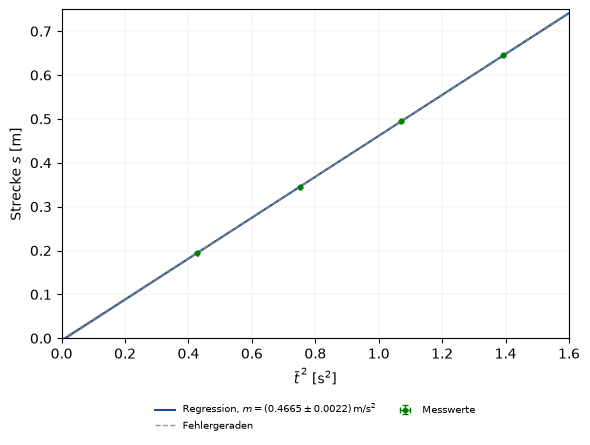

In [21]:
fig1, ax1 = plt.subplots(figsize=FIGSIZE)
zeichne_fit(ax1, fit, X_MIN, X_MAX, LABEL_MESS, LABEL_GERADE)
ax1.set_xlim(X_MIN, X_MAX)
ax1.set_ylim(Y_MIN, Y_MAX)
ax1.set_xlabel(X_LABEL)
ax1.set_ylabel(Y_LABEL)
ax1.grid(True, lw=0.3, alpha=0.4)
legende(ax1, unten=LEGENDE_UNTEN)
speichern(fig1, DATEINAME)

## Teil 3 – Export

In [22]:
export_ergebnisse()

9 Ergebnisse, 1 σ-Vergleiche -> export/ergebnisse.tex

  export/ergebnisse.tex
  export/budget/a_V.tex
  export/budget/a_th.tex
  export/budget/sin_phi.tex
  export/diagramme/s_t2.png
  export/formeln/a_V.tex
  export/formeln/a_th.tex
  export/formeln/sin_phi.tex
  export/formeln/t2.tex
  export/tabellen/fit_V.tex
  export/tabellen/konstanten.tex
  export/tabellen/zeiten_V.tex
